# Frente C: verificación de H1 a H4 (sección 3)

El notebook 03 responde **qué tan bien clasifica** el algoritmo. Este responde otra pregunta: **¿cada técnica que agregamos realmente sirve?** El anteproyecto planteó cuatro hipótesis, una por técnica nueva, y acá se pone a prueba cada una.

Todas siguen el mismo esquema:

1. Se calcula una medida **para cada paciente** con dos variantes: con la técnica (**variante a**) y sin ella o con la alternativa (**variante b**).
2. Se comparan las dos variantes **paciente por paciente** con la prueba de Wilcoxon.
3. Se grafica el resultado.

El código está en `src/estadios/evaluacion/hipotesis.py`. Cada función devuelve una `Comparacion` con los valores de la variante a, los de la variante b y el **p-valor**. Las figuras se guardan en `informe/figuras/` con prefijo `h_`.

| Hipótesis | Qué se compara | Medida por paciente | Se espera | Depende de |
|---|---|---|---|---|
| H1 | Multitaper vs. Welch | Variación entre épocas vecinas del mismo estadio | a < b | Datos reales |
| H2 | Woody vs. promedio común | Error de forma de la onda simulada | a < b | Ya funciona |
| H3 | Con CSP vs. sin CSP | F1 de N1 y F1 de REM | a > b | Ya funciona |
| H4 (1) | Después vs. antes de remover | Pico del promedio alrededor del latido | a < b | Frente A |
| H4 (2) | Con etapas vs. sin etapas | κ | a > b | Frente A y datos reales |

**Con qué pacientes se prueba cada hipótesis:**

- **H1, H2 y el residuo de H4** analizan las señales directamente, así que usan los registros de los **pacientes de prueba**.
- **H3 y el κ de H4** clasifican, así que siguen el esquema del notebook 03: ajustan con entrenamiento y evalúan con prueba.

Sin datos reales, todo usa registros y tablas sintéticas.

## Preparación

- **Entorno y `guardar()`:** las mismas celdas que en el notebook 03. Se paran en `codigo/`, ubican el paquete `estadios`, deciden si hay datos reales y guardan las figuras en `informe/figuras/`.

In [27]:
# Entorno común a todos los notebooks: se corre desde codigo/ para que DIR_DATOS
# ("data" o $ESTADIOS_DATOS) apunte al mismo lugar que los scripts.
import os
import sys
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

# Si el paquete no está instalado con `pip install -e .`, se usa directamente codigo/src.
# Las dependencias (numpy, scipy, pandas, matplotlib, mne, scikit-learn) sí tienen que
# estar instaladas en el Python de este kernel.
try:
    import estadios  # noqa: F401
except ModuleNotFoundError:
    sys.path.insert(0, str(Path.cwd() / "src"))
FIGURAS = Path.cwd().parent / "informe" / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)

import numpy as np
import matplotlib.pyplot as plt

from estadios.comun.config import Config
from estadios.comun.constantes import NOMBRES_ESTADIOS, N_ESTADIOS, SIN_ANOTAR
from estadios.datos.carga import ids_disponibles

USAR_DATOS_REALES = len(ids_disponibles()) > 0
print("Datos reales" if USAR_DATOS_REALES else "Sin datos descargados: se usan los sintéticos")

Sin datos descargados: se usan los sintéticos


In [28]:
def guardar(fig, nombre):
    """Guarda la figura en informe/figuras/ para incluirla con \\includegraphics."""
    fig.savefig(FIGURAS / f"{nombre}.pdf", bbox_inches="tight")

### Cómo se grafica cada comparación: `mostrar()`

Dibuja un boxplot por variante y une con una línea gris los dos valores de **cada paciente**. Si casi todas las líneas bajan (o suben) en el mismo sentido, la técnica tiene un efecto consistente. En el título va el p-valor, que también se imprime.

In [29]:
from dataclasses import replace

from estadios.evaluacion import hipotesis

def mostrar(nombre, comparacion, etiqueta_a, etiqueta_b, ylabel):
    print(f"{nombre}: p = {comparacion.p_valor:.4f}")
    fig, ax = plt.subplots(figsize=(4, 4))
    for a, b in zip(comparacion.variante_a, comparacion.variante_b):
        ax.plot([0, 1], [a, b], c="gray", alpha=0.5)
    ax.boxplot([comparacion.variante_a, comparacion.variante_b], positions=[0, 1],
               tick_labels=[etiqueta_a, etiqueta_b])
    ax.set(ylabel=ylabel, title=f"{nombre} (p = {comparacion.p_valor:.3g})")
    guardar(fig, f"h_{nombre.lower()}")

## La prueba de Wilcoxon (`comparar_por_paciente`)

Compara las dos variantes paciente por paciente y da un p-valor: la probabilidad de ver una diferencia tan consistente si en realidad la técnica no tuviera efecto. Si es menor que 0,05, se considera que el efecto es real.

El detalle está en la subsección siguiente, que se puede plegar.

### Wilcoxon en detalle

##### Por qué se compara paciente por paciente

Los pacientes son muy distintos entre sí: uno tiene el doble de amplitud que otro, otro duerme mal. Si se compararan los promedios de las dos variantes, esa variabilidad taparía el efecto. Comparando **cada paciente consigo mismo**, se elimina.

##### Cómo funciona la prueba de rangos con signo

1. Para cada paciente se calcula la diferencia entre las dos variantes: $d_i = a_i - b_i$.
2. Se ordenan las diferencias por tamaño, sin importar el signo, y se les asigna un rango: 1 a la más chica.
3. Se suman los rangos de las diferencias positivas por un lado y los de las negativas por otro.
4. Si la técnica no tuviera efecto, las dos sumas deberían ser parecidas: unas veces gana a y otras b. Si una suma es mucho más grande que la otra, el efecto es consistente.

**Ejemplo con 5 pacientes:**

| Paciente | a | b | d = a − b | Rango de \|d\| |
|---|---|---|---|---|
| 1 | 0,10 | 0,15 | −0,05 | 3 |
| 2 | 0,12 | 0,14 | −0,02 | 1 |
| 3 | 0,09 | 0,16 | −0,07 | 4 |
| 4 | 0,11 | 0,14 | −0,03 | 2 |
| 5 | 0,08 | 0,17 | −0,09 | 5 |

Las cinco diferencias son negativas: a fue menor en todos. La suma de rangos positivos es 0 y la de negativos 15, la máxima diferencia posible.

##### Por qué Wilcoxon y no una prueba t

No supone que las diferencias sigan una distribución normal. Con pocos pacientes, como los 12 a 16 que van a quedar de prueba, es lo más seguro.

##### Un límite: con pocos pacientes, el p-valor no puede ser muy chico

**Qué es el p-valor.** Es la probabilidad de obtener un resultado **igual o más extremo** que el observado si la técnica no tuviera ningún efecto. Para calcularlo hay que saber qué resultados son posibles bajo esa suposición y cuán probable es cada uno.

**1. Qué supone la hipótesis nula.** Si la técnica no tiene efecto, para cada paciente es igual de probable que gane a o que gane b. Cada diferencia $d_i$ tiene la misma probabilidad de ser positiva o negativa, como tirar una moneda.

**2. Cuántas combinaciones hay.** Con $n$ pacientes, cada uno tiene 2 signos posibles, así que hay $2^n$ combinaciones de signos, todas igual de probables. Los rangos (1, 2, …, n) quedan fijos; lo único que cambia es qué signo le toca a cada uno.

**3. El caso más extremo.** Es que **todas** las diferencias tengan el mismo signo. Hay una sola combinación con todos negativos, así que su probabilidad es $1/2^n$.

**4. Por qué se multiplica por 2.** La prueba es **bilateral**: no supone de antemano cuál variante gana. Entonces "todos positivos" cuenta como igual de extremo que "todos negativos". Son 2 combinaciones de $2^n$:

$$p_{\min} = \frac{2}{2^n}$$

Como no hay nada más extremo que "todos en el mismo sentido", ese es el p-valor más chico que se puede obtener con $n$ pacientes.

**Ejemplo con 3 pacientes.** Hay $2^3 = 8$ combinaciones de signos para los rangos 1, 2 y 3:

| Rango 1 | Rango 2 | Rango 3 | Suma de rangos positivos |
|---|---|---|---|
| − | − | − | **0** ← el más extremo hacia un lado |
| + | − | − | 1 |
| − | + | − | 2 |
| − | − | + | 3 |
| + | + | − | 3 |
| + | − | + | 4 |
| − | + | + | 5 |
| + | + | + | **6** ← el más extremo hacia el otro |

Si los 3 pacientes van en el mismo sentido, el p-valor es 2/8 = 0,25. Con 3 pacientes es imposible llegar a 0,05, por más que la técnica funcione perfecto.

**Con más pacientes:**

| Pacientes | $2^n$ | $p_{\min} = 2/2^n$ | ¿Puede bajar de 0,05? |
|---|---|---|---|
| 3 | 8 | 0,25 | No |
| 5 | 32 | 0,0625 | No: el ejemplo de arriba no llega, aunque los cinco coinciden |
| 6 | 64 | 0,031 | Sí, solo si todos coinciden (es lo que da con los datos sintéticos) |
| 10 | 1024 | 0,002 | Sí |
| 14 | 16384 | 0,0001 | Sí, con margen |

Por eso conviene tener al menos 6 pacientes de prueba, y es bueno mencionar este límite en el informe. Con los 12 a 16 pacientes de prueba previstos no hay problema.

**Un detalle:** esta cuenta exacta vale cuando no hay empates ni diferencias exactamente iguales a cero. Con pocos pacientes, SciPy (que usa `comparar_por_paciente`) calcula el p-valor exacto de esta forma; si hay empates o ceros, usa una aproximación normal y el p-valor puede diferir un poco.

##### Cómo se calcula el p-valor de cualquier resultado

La suma de rangos no se reemplaza directamente en una fórmula: se usa para decidir **qué combinaciones se cuentan**.

**1. Se toma la suma más chica de las dos:**

$$w = \min(W^+,\ W^-)$$

donde $W^+$ es la suma de rangos positivos y $W^-$ la de negativos. Las dos suman siempre $T = n(n+1)/2$, la suma de todos los rangos (con 5 pacientes, $T = 15$).

**2. Se cuenta cuántas combinaciones son igual o más extremas, hacia los dos lados:**

$$p = \frac{N(W^+ \le w) \;+\; N(W^+ \ge T - w)}{2^n}$$

$N(\ldots)$ es la cantidad de combinaciones de signos que cumplen esa condición, y se lee de la tabla de abajo. El primer término cuenta el extremo de un lado y el segundo, el del otro. Como la distribución es simétrica, los dos son iguales y queda:

$$p = \frac{2 \cdot N(W^+ \le w)}{2^n}$$

**Cuántas combinaciones dan cada suma, con 5 pacientes** (de las $2^5 = 32$):

| $W^+$ | 0 | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 | 11 | 12 | 13 | 14 | 15 |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| Combinaciones | 1 | 1 | 1 | 2 | 2 | 3 | 3 | 3 | 3 | 3 | 3 | 2 | 2 | 1 | 1 | 1 |

Es simétrica alrededor de 7,5, donde gana a la mitad de las veces y b la otra mitad.

**Ejemplos:**

| $W^+$ | $W^-$ | $w$ | $N(W^+ \le w)$ | $N(W^+ \ge 15 - w)$ | p |
|---|---|---|---|---|---|
| 0 | 15 | 0 | columna 0: **1** | columna 15: **1** | 2/32 = **0,0625** |
| 1 | 14 | 1 | columnas 0–1: 1 + 1 = **2** | columnas 14–15: 1 + 1 = **2** | 4/32 = **0,125** |
| 3 | 12 | 3 | columnas 0–3: 1 + 1 + 1 + 2 = **5** | columnas 12–15: 2 + 1 + 1 + 1 = **5** | 10/32 ≈ **0,31** |

- **$W^+ = 0$, $W^- = 15$:** los cinco pacientes en el mismo sentido, el caso del ejemplo de arriba. Es el más extremo posible, y su p-valor es el $p_{\min}$.
- **$W^+ = 1$, $W^- = 14$:** el paciente con la diferencia más chica (rango 1) fue para el otro lado.
- **$W^+ = 3$, $W^- = 12$:** un resultado menos consistente.

Cuanto más chica es $w$, menos combinaciones se cuentan y más chico es el p-valor. SciPy hace exactamente esto: arma la tabla para el $n$ que corresponda y suma las columnas de los extremos.

##### Un detalle del código

Si las dos variantes son idénticas en todos los pacientes, Wilcoxon no está definido. En ese caso la función devuelve p = 1.

##### Qué muestra la celda siguiente

1. Reproduce el ejemplo de los 5 pacientes con `comparar_por_paciente`.
2. Calcula el p-valor mínimo posible según la cantidad de pacientes.
3. Arma la tabla de combinaciones para 5 pacientes recorriendo las 32 combinaciones de signos, y calcula el p-valor de cada ejemplo contando a mano y con SciPy: tienen que coincidir.

In [30]:
import pandas as pd
from scipy.stats import rankdata

a = np.array([0.10, 0.12, 0.09, 0.11, 0.08])
b = np.array([0.15, 0.14, 0.16, 0.14, 0.17])
d = a - b
rangos = rankdata(np.abs(d))
print(pd.DataFrame({"a": a, "b": b, "d = a − b": d, "rango de |d|": rangos}, index=range(1, 6)).round(3), "\n")
print(f"Suma de rangos positivos: {rangos[d > 0].sum():g}   negativos: {rangos[d < 0].sum():g}")
print(f"p-valor con comparar_por_paciente: {hipotesis.comparar_por_paciente(a, b).p_valor:.4f}\n")

print("p-valor mínimo posible (todos los pacientes en el mismo sentido):")
for n in (5, 6, 10, 14, 16):
    print(f"  {n:2d} pacientes: {2 / 2**n:.5f}")

# Tabla de combinaciones para 5 pacientes: se recorren las 2^5 = 32 combinaciones de signos.
from itertools import product
from scipy.stats import wilcoxon

n = 5
T = n * (n + 1) // 2
sumas_positivas = [sum(r for r, s in zip(range(1, n + 1), signos) if s > 0)
                   for signos in product([-1, 1], repeat=n)]
conteo = np.bincount(sumas_positivas, minlength=T + 1)
print("\nCombinaciones por suma de rangos positivos (n = 5):")
print(pd.DataFrame([conteo], index=["Combinaciones"], columns=range(T + 1)))

print("\nW+   W-   w   N(W+ <= w)   N(W+ >= T - w)   p a mano   p con SciPy")
for w_pos in (0, 1, 3):
    w = min(w_pos, T - w_pos)
    izquierda, derecha = conteo[: w + 1].sum(), conteo[T - w:].sum()
    p_mano = (izquierda + derecha) / 2**n
    # Diferencias con esos signos: el rango r tiene |d| = r y es positivo solo si entra en W+.
    positivos = {0: [], 1: [1], 3: [1, 2]}[w_pos]
    d = np.array([r if r in positivos else -r for r in range(1, n + 1)], dtype=float)
    p_scipy = wilcoxon(d).pvalue
    print(f"{w_pos:2d}   {T - w_pos:2d}   {w}   {izquierda:10d}   {derecha:14d}   {p_mano:8.4f}   {p_scipy:11.4f}")

      a     b  d = a − b  rango de |d|
1  0.10  0.15      -0.05           3.0
2  0.12  0.14      -0.02           1.0
3  0.09  0.16      -0.07           4.0
4  0.11  0.14      -0.03           2.0
5  0.08  0.17      -0.09           5.0 

Suma de rangos positivos: 0   negativos: 15
p-valor con comparar_por_paciente: 0.0625

p-valor mínimo posible (todos los pacientes en el mismo sentido):
   5 pacientes: 0.06250
   6 pacientes: 0.03125
  10 pacientes: 0.00195
  14 pacientes: 0.00012
  16 pacientes: 0.00003

Combinaciones por suma de rangos positivos (n = 5):
               0   1   2   3   4   5   6   7   8   9   10  11  12  13  14  15
Combinaciones   1   1   1   2   2   3   3   3   3   3   3   2   2   1   1   1

W+   W-   w   N(W+ <= w)   N(W+ >= T - w)   p a mano   p con SciPy
 0   15   0            1                1     0.0625        0.0625
 1   14   1            2                2     0.1250        0.1250
 3   12   3            5                5     0.3125        0.3125


## H1: el multitaper varía menos que Welch entre épocas de un mismo estadio

Se mide cuánto cambia el espectro entre épocas **consecutivas del mismo estadio**, con cada método, en el canal C4. Se espera que el multitaper (a) varíe **menos** que Welch (b). Se calcula por banda y frecuencia por frecuencia.

**Cuidado:** con los registros sintéticos este resultado no sirve. Su potencia por banda es exactamente la misma en todas las épocas de un estadio, lo que favorece a Welch y hace que H1 dé al revés. **H1 se evalúa con datos reales.**

H1_bandas: p = 0.0312
H1_frecuencias: p = 0.0312


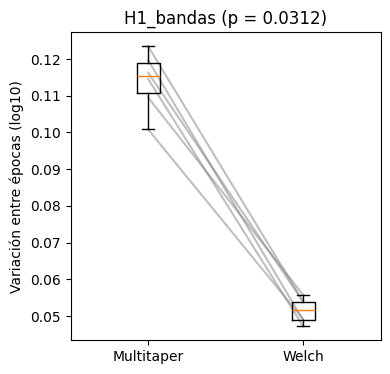

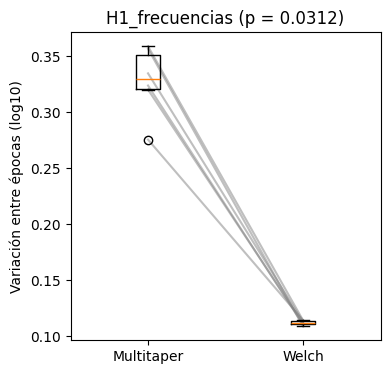

In [31]:
from estadios.comun.sintetico import registro_sintetico
from estadios.datos.carga import cargar_registro
from estadios.datos.particion import particion_por_paciente

if USAR_DATOS_REALES:
    _, ids_prueba = particion_por_paciente(ids_disponibles())
    registros = [cargar_registro(i) for i in ids_prueba]
else:
    registros = [registro_sintetico(semilla=s) for s in range(6)]

# Por banda (lo que usan los descriptores) y frecuencia por frecuencia (donde el
# multitaper debería mostrar su ventaja: integrar una banda ya promedia el ruido).
h1 = hipotesis.h1_variabilidad_espectral(registros)
mostrar("H1_bandas", h1, "Multitaper", "Welch", "Variación entre épocas (log10)")
h1_f = hipotesis.h1_variabilidad_espectral(registros, por_frecuencia=True)
mostrar("H1_frecuencias", h1_f, "Multitaper", "Welch", "Variación entre épocas (log10)")

### H1 en detalle

##### El problema de medirlo

En datos reales no se conoce el espectro "verdadero" de una época, así que no se puede medir directamente el error de cada método.

##### La idea para medirlo igual

Si dos épocas seguidas son del **mismo estadio**, su espectro real debería ser parecido. Entonces, lo que cambia entre ellas es sobre todo **ruido de estimación**. Un método menos ruidoso debería variar menos entre épocas vecinas del mismo estadio.

##### Cómo se calcula (`h1_variabilidad_espectral`)

1. Se corta el canal C4 en épocas de 30 s.
2. Se calcula el espectro de cada época con multitaper y con Welch.
3. Se calcula el logaritmo de la potencia. El logaritmo hace que importe el cambio relativo: pasar de 10 a 20 pesa lo mismo que de 100 a 200.
4. Para cada par de épocas **consecutivas y del mismo estadio**, se calcula la diferencia absoluta del logaritmo. Se promedia sobre todos los pares: queda un número por paciente y por método.

##### Por qué se calcula de dos formas

- **Por banda** (δ, θ, α, σ, β), que es lo que usan los descriptores.
- **Frecuencia por frecuencia**, entre 0,5 y 30 Hz.

Sumar la potencia de toda una banda ya promedia muchas frecuencias y elimina gran parte del ruido en **los dos** métodos. Por eso, por banda la diferencia es chica, y frecuencia por frecuencia es donde se ve la ventaja del multitaper. Con ruido blanco se comprobó: por banda los dos métodos varían casi lo mismo, y frecuencia por frecuencia el multitaper varía alrededor de un tercio menos (ver el test `test_h1_multitaper_varia_menos_por_frecuencia_en_ruido_blanco`).

## H2: Woody recupera la forma de la onda lenta mejor que el promedio ordinario

Se insertan ondas lentas de forma conocida, corridas al azar, en EEG real de vigilia, y se mide cuánto se equivoca cada método al recuperar su forma. Se espera que Woody (a) tenga **menos** error que el promedio común (b). Con datos sintéticos, Woody tuvo alrededor de 14 % de error y el promedio común alrededor de 40 %.

H2: p = 0.0312


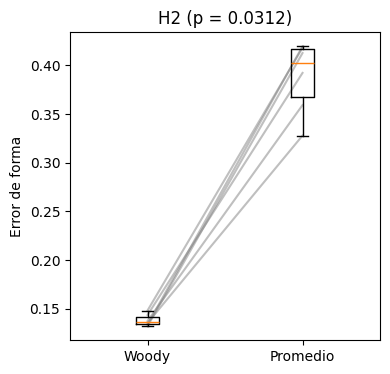

In [32]:
from estadios.comun.constantes import EEG_F4, W

eeg_vigilia = []
for r in registros:
    n = int(30 * r.fs)
    epocas_w = np.flatnonzero(r.estadios == W)[:20]
    eeg_vigilia.append(np.concatenate([r.senales[EEG_F4][i * n:(i + 1) * n] for i in epocas_w]))

h2 = hipotesis.h2_recuperacion_de_forma(eeg_vigilia, registros[0].fs)
mostrar("H2", h2, "Woody", "Promedio", "Error de forma")

### H2 en detalle

##### El problema

En datos reales no se sabe cuál es la forma "verdadera" de las ondas lentas de un paciente, así que no hay contra qué comparar.

##### La solución: una simulación controlada (`h2_recuperacion_de_forma`)

1. **Se arma una onda lenta de forma conocida** (`onda_lenta_modelo`): un coseno de 0,8 Hz con envolvente gaussiana y 80 µV de pico negativo. Dura alrededor de 1 s y cumple el criterio de detección de ondas lentas.
2. **Se toma EEG real de vigilia** del canal F4: las primeras 20 épocas W de cada paciente. Se usa vigilia porque casi no tiene ondas lentas propias: funciona como "ruido de fondo" realista.
3. **Se insertan 40 copias de la onda**, cada una **corrida al azar** hasta ±0,25 s respecto del centro de su ventana. Eso imita lo que pasa en la realidad: el ruido corre el pico detectado y las ondas no quedan bien alineadas.
4. **Se recupera la forma de dos maneras:**
   - **promedio común:** se promedian las 40 ventanas tal como están;
   - **Woody:** alinea iterativamente cada ventana con el promedio, recalcula y repite hasta que los corrimientos dejan de cambiar.
5. **Se mide el error** de cada forma recuperada (`error_de_forma`): el valor eficaz de la diferencia con la onda real, dividido por el de la onda real. Antes se busca el mejor corrimiento global, porque ningún método puede saber dónde está "el centro verdadero"; lo que se evalúa es la **forma**.

##### Por qué el promedio común falla

Al promediar ondas desalineadas, los picos no coinciden y se "borronean": el resultado sale más ancho y más chico que la onda real. Woody las alinea antes de promediar.

## H3: CSP mejora el F1 de N1 y REM

Se arma el clasificador con CSP (a) y sin CSP (b) y se compara el F1 de N1 y de REM en cada paciente de prueba. Se espera que con CSP sea **mayor**. Con CSP está activo el desempate N1/REM de `reglas.desempatar_con_csp`.

H3_N1: p = 1.0000
H3_R: p = 1.0000


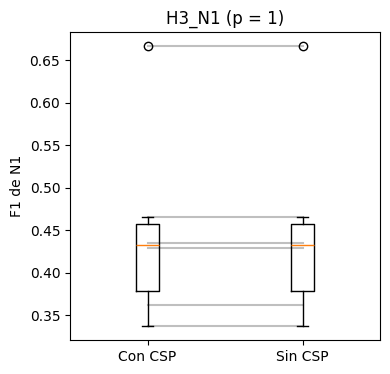

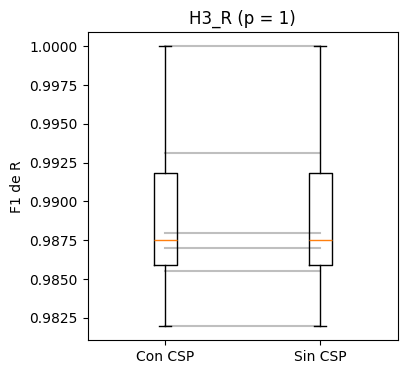

In [33]:
from estadios.comun.sintetico import tabla_sintetica
from estadios.pipeline import obtener_tabla

cfg = Config()
if USAR_DATOS_REALES:
    ids_entrenamiento, ids_prueba = particion_por_paciente(ids_disponibles())
    entrenamiento = [obtener_tabla(i, cfg) for i in ids_entrenamiento]
    prueba = [obtener_tabla(i, cfg) for i in ids_prueba]
else:
    entrenamiento = [tabla_sintetica(semilla=s) for s in range(8)]
    prueba = [tabla_sintetica(semilla=s) for s in range(100, 106)]

h3 = hipotesis.h3_aporte_csp(entrenamiento, prueba, cfg)
for estadio, comparacion in h3.items():
    mostrar(f"H3_{estadio}", comparacion, "Con CSP", "Sin CSP", f"F1 de {estadio}")

### H3 en detalle

##### Cómo se calcula (`h3_aporte_csp`)

1. Se arma el clasificador **dos veces**: con CSP (variante a) y sin CSP (variante b). Lo único que cambia es si `"csp"` está en `grupos` de la configuración.
2. Los dos se ajustan con los pacientes de entrenamiento.
3. Para cada paciente de prueba se calcula el F1 de N1 y el F1 de REM con cada versión.
4. Se compara por separado: una prueba de Wilcoxon para N1 y otra para REM.

##### Por qué el F1 y no κ

El desempate solo toca épocas N1 o REM. Su efecto en κ, que mira toda la noche, puede ser chico y quedar tapado. El F1 de esos dos estadios lo muestra directamente.

## H4: la remoción de artefactos y la HRV mejoran el acuerdo

Tiene dos partes: primero se verifica que la remoción funcione (el artefacto desaparece), y después que sirva para clasificar (κ mejora).

**Relación con la devolución:** la cátedra dudaba de que la remoción del artefacto cardíaco fuera necesaria. H4 es justamente lo que responde esa pregunta: si la parte 1 muestra que el residuo antes de remover ya era chico, o la parte 2 no muestra mejora en κ, la conclusión es que no hacía falta. Eso también es un resultado válido para el informe.

### H4, parte 1: el artefacto cardíaco desaparece

Se compara el promedio del EEG alrededor de cada latido después (a) y antes (b) de restar la plantilla cardíaca. Se espera que después quede **cerca de cero**.

**Hoy:** la celda avisa "Pendiente del Frente A", porque necesita la detección de latidos y la remoción cardíaca. Va a correr sola cuando estén implementadas.

In [34]:
try:
    h4_residuo = hipotesis.h4_residuo_cardiaco(registros, cfg)
    mostrar("H4_residuo", h4_residuo, "Después", "Antes", "Promedio alrededor del latido (µV)")
except NotImplementedError as pendiente:
    print(f"Pendiente del Frente A: {pendiente}. Esta celda corre sola cuando esté implementado.")

Pendiente del Frente A: Etapa 4. Esta celda corre sola cuando esté implementado.


#### H4, parte 1 en detalle (`h4_residuo_cardiaco`)

1. Se detectan los latidos en el ECG (Pan-Tompkins, Frente A).
2. **"Antes"** es la señal ya filtrada (y sin artefacto ocular, si esa etapa está activa). **"Después"** es esa misma señal tras restar la plantilla cardíaca. Así se aísla el efecto de la etapa 4.
3. Para cada una se calcula el **promedio del EEG alrededor de cada latido**. Como el EEG no está sincronizado con el corazón, al promediar muchos latidos el EEG se cancela y solo queda la forma del artefacto.
4. Se toma el pico máximo (en valor absoluto) de ese promedio, promediado entre los 4 canales de EEG: un número por paciente.

### H4, parte 2: mejora el κ

Se clasifica con dos configuraciones completas, con etapas (a) y sin etapas (b), y se compara el κ de cada paciente de prueba. Se espera que con etapas sea **mayor**.

H4_kappa: p = 1.0000


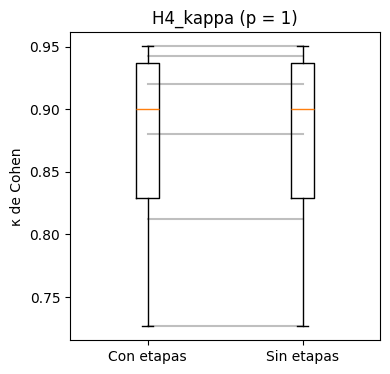

In [35]:
from estadios.comun.config import GRUPOS_DESCRIPTORES

cfg_sin = replace(
    cfg,
    preprocesamiento=replace(cfg.preprocesamiento, remover_ocular=False, remover_cardiaco=False),
    clasificacion=replace(cfg.clasificacion,
                          grupos=tuple(g for g in GRUPOS_DESCRIPTORES if g != "hrv")),
)
if USAR_DATOS_REALES:
    sin_etapas = ([obtener_tabla(i, cfg_sin) for i in ids_entrenamiento],
                  [obtener_tabla(i, cfg_sin) for i in ids_prueba])
else:
    sin_etapas = (entrenamiento, prueba)  # Con sintéticos solo se prueba que corra.

h4_kappa = hipotesis.h4_aporte_al_acuerdo((entrenamiento, prueba), sin_etapas, cfg)
mostrar("H4_kappa", h4_kappa, "Con etapas", "Sin etapas", "κ de Cohen")

#### H4, parte 2 en detalle (`h4_aporte_al_acuerdo`)

1. Se arman **dos configuraciones completas**:
   - **con etapas (a):** remoción de los artefactos ocular y cardíaco, y la regla de REM puede usar la HRV;
   - **sin etapas (b):** sin remoción de artefactos, y la regla de REM usa solo el EOG.
2. Cada configuración necesita **sus propios descriptores**, porque cambia el preprocesamiento. Con datos reales, `obtener_tabla` calcula y guarda en caché una segunda versión de los descriptores de cada paciente. La primera vez tarda.
3. Se clasifica con cada una y se compara el κ de cada paciente de prueba.

**Con datos sintéticos** no se puede probar de verdad: las dos variantes usan las mismas tablas, y la celda solo verifica que el código corra.